In [1]:
!pip install kaggle
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [2]:
!kaggle competitions download -c dog-breed-identification

 97% 667M/691M [00:03<00:00, 170MB/s]
100% 691M/691M [00:03<00:00, 214MB/s]


In [3]:
!unzip dog-breed-identification.zip -d dog-breed-identification

Выходные данные были обрезаны до нескольких последних строк (5000).
  inflating: dog-breed-identification/train/83bc62b0fffa99a9c94ba0b67a5f7395.jpg  
  inflating: dog-breed-identification/train/83bcff6b55ee179a7c123fa6103c377a.jpg  
  inflating: dog-breed-identification/train/83be6d622ab74a5e7e08b53eb8fd566a.jpg  
  inflating: dog-breed-identification/train/83c2d7419b0429b9fe953bc1b6cddbec.jpg  
  inflating: dog-breed-identification/train/83cf7d7cd2a759a93e2ffd95bea9c6fb.jpg  
  inflating: dog-breed-identification/train/83d405858f0931722ef21e8ac0adee4d.jpg  
  inflating: dog-breed-identification/train/83d4125a4c3c7dc5956563276cb1cd74.jpg  
  inflating: dog-breed-identification/train/83f0bb565b2186dbcc6a9d009cb26ff2.jpg  
  inflating: dog-breed-identification/train/83fad0718581a696132c96c166472627.jpg  
  inflating: dog-breed-identification/train/83fbbcc9a612e3f712b1ba199da61f20.jpg  
  inflating: dog-breed-identification/train/8403d8936430c2f05ab7d74d23c2c0cb.jpg  
  inflating: dog-br

Нужные импорты:

In [4]:
import os
import pandas as pd
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import seaborn as sns
from matplotlib import pyplot as plt

Датасет: (labels.csv - соответствие картинки и породы, картинки имеют название вида {id}.jpg)

In [5]:
class DogBreedDataset(Dataset):
    def __init__(self, labels_path, root_dir, transform=None):
        self.labels_df = pd.read_csv(labels_path)
        self.root_dir = root_dir
        self.transform = transform

        self.label_encoder = LabelEncoder()
        self.labels_df['breed'] = self.label_encoder.fit_transform(self.labels_df['breed'])

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, idx):
        img_name = os.path.join(self.root_dir, self.labels_df.iloc[idx, 0] + '.jpg')
        image = Image.open(img_name)

        label = self.labels_df.iloc[idx, 1]

        if self.transform:
            resized_image = self.transform(image)

        return resized_image, label

В целях борьбы с переобучением, примением аугментации данных:

In [13]:
transform_auc = transforms.Compose([
    transforms.Resize((240, 240)),
    transforms.RandomHorizontalFlip(p=0.7),
    transforms.RandomRotation(12),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


In [7]:
def plot_it(train_, test_):

    sns.lineplot(x=[i + 1 for i in range(len(train_))], y=train_)
    sns.lineplot(x=[i + 1 for i in range(len(test_))], y=test_)

    plt.show()

In [8]:
dataset = DogBreedDataset(
    labels_path='/content/dog-breed-identification/labels.csv',
    root_dir='/content/dog-breed-identification/train',
    transform=transform_auc)

train_size = int(0.66 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = torch.utils.data.random_split(dataset,
                                                            [train_size, test_size])

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, num_workers=2)

In [9]:
torch.cuda.empty_cache()

Epoch [1/8], Loss: 3.5334


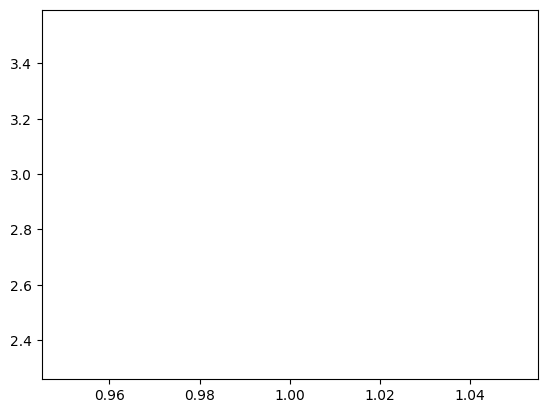

Epoch [2/8], Loss: 2.5096


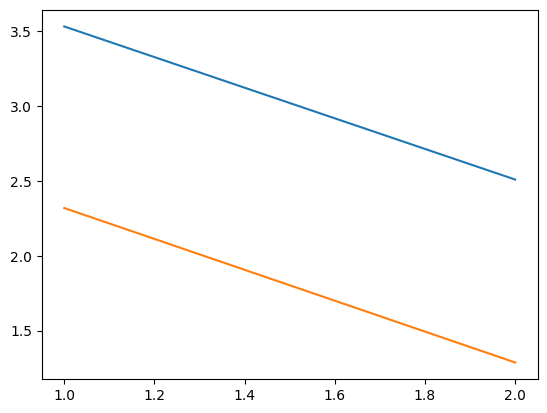

Epoch [3/8], Loss: 1.5652


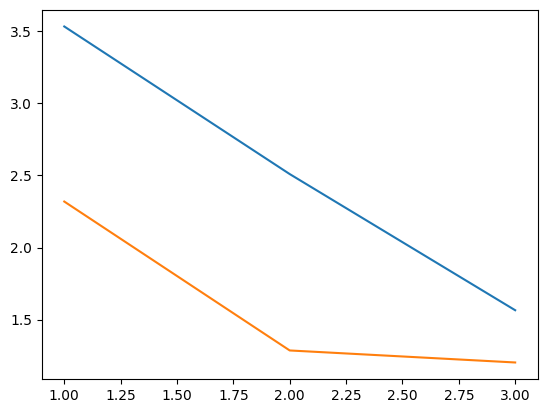

Epoch [4/8], Loss: 1.8736


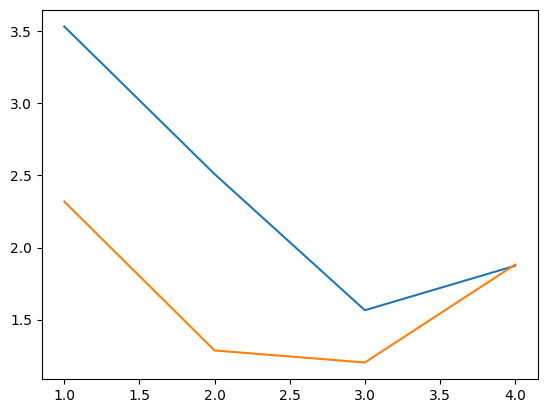

Epoch [5/8], Loss: 1.2434


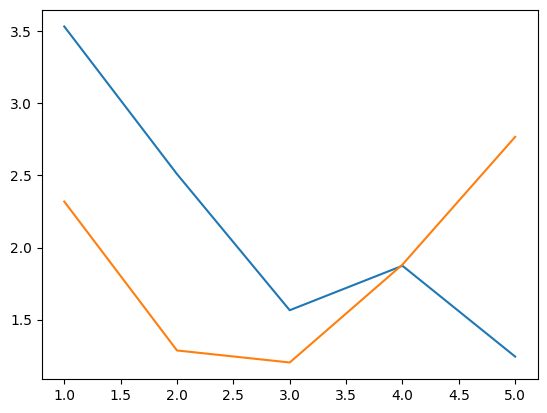

Epoch [6/8], Loss: 1.3368


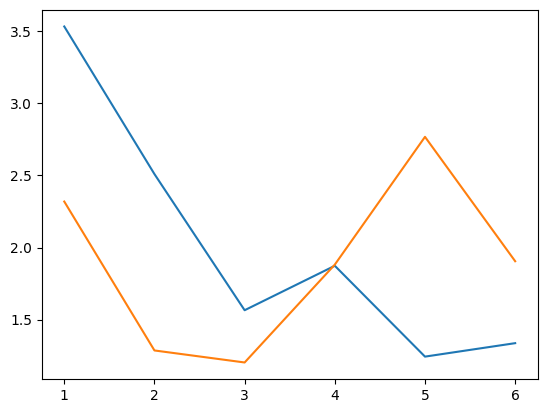

Epoch [7/8], Loss: 0.7229


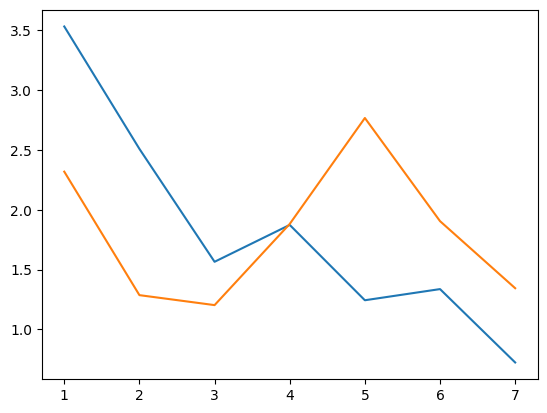

Epoch [8/8], Loss: 0.3725


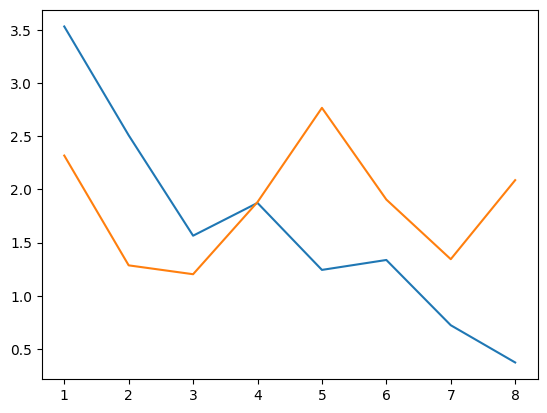

Accuracy: 74.14%


In [11]:
device = 'cuda'
model = models.resnet50(pretrained=True)
model.fc = nn.Sequential(nn.Linear(model.fc.in_features, 260),
                         nn.LeakyReLU(0.02),
                         nn.Linear(260, 120))
  # Я АХУЕЛА ОТ ЖИЗНИ ПОТОМУ ЧТО БЕЗ РЕЗНЕТА50 НИ ХУ Я НЕ РАБОТАЕТ!
model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=8e-4, momentum=0.8)
num_epochs = 15

train_losses, test_losses = [], []
for epoch in range(num_epochs):
    model.train()

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

    train_losses.append(loss.item())

    print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {loss.item():.4f}')

    model.eval()
    correct = 0
    total = 0
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), torch.Tensor(labels).to(device)
        outputs = model(inputs)

        loss = criterion(outputs, labels)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    test_losses.append(loss.item())
    accuracy = 100 * correct / total
    plot_it(train_losses, test_losses)
print(f'Accuracy: {accuracy:.2f}%')


In [ ]:
model.eval()
correct = 0
total = 0
for inputs, labels in test_loader:
    inputs, labels = inputs.to(device), labels.to(device)
    outputs = model(inputs)
    _, predicted = torch.max(outputs, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f'Accuracy: {accuracy:.2f}%')

OutOfMemoryError: CUDA out of memory. Tried to allocate 234.00 MiB. GPU 0 has a total capacity of 14.74 GiB of which 106.12 MiB is free. Process 2139 has 14.63 GiB memory in use. Of the allocated memory 13.76 GiB is allocated by PyTorch, and 751.79 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

Сделаем сабмишен со скорами данной модели. В соревновании просят вероятности классов, поэтому используем софтмакс:

In [18]:
import torch.nn.functional as F


class TestDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_list = os.listdir(root_dir)
        self.image_list.sort()

    def __len__(self):
        return len(self.image_list)

    def __getitem__(self, idx):
        img_name = self.image_list[idx]
        img_path = os.path.join(self.root_dir, img_name)
        image = Image.open(img_path)

        if self.transform:
            resized_image = self.transform(image)

        return resized_image, img_name[:-4]

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

test_image_dir = '/content/dog-breed-identification/test'
test_dataset = TestDataset(test_image_dir, transform=transform_auc)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

labels_df = pd.read_csv('/content/dog-breed-identification/labels.csv')
label_names = sorted(labels_df['breed'].unique())

output_file = 'submission_cv.csv'
with open(output_file, 'w') as f:
    header = 'id,' + ','.join(label_names) + '\n'
    f.write(header)

    for inputs, img_ids in test_loader:
        inputs = inputs.to(device)
        with torch.no_grad():
            outputs = model(inputs)
            print("f")
            probabilities = F.softmax(outputs, dim=1)

        for img_id, probs in zip(img_ids, probabilities):
            probs_str = ','.join(map(str, probs.cpu().numpy()))
            line = f"{img_id},{probs_str}\n"
            f.write(line)

f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
f
